In [11]:
# ==========================================================
# STEP 1: INSTALL & DOWNLOAD DATASET VIA KAGGLEHUB
# ==========================================================
!pip install -q kagglehub

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from google.colab import files
import sklearn.metrics as metrics
import kagglehub

# Download Food-101 dataset
print("Downloading Food-101 dataset via kagglehub...")
dataset_path = kagglehub.dataset_download("dansbecker/food-101")
print("Dataset downloaded to:", dataset_path)

# Locate the images directory
# Note: dansbecker/food-101 typically extracts directly or into an 'images' subfolder
images_dir = os.path.join(dataset_path, "food-101", "food-101", "images")
if not os.path.exists(images_dir):
    images_dir = os.path.join(dataset_path, "images")
if not os.path.exists(images_dir):
    images_dir = dataset_path

print("Using image directory:", images_dir)

Using Colab cache for faster access to the 'food-101' dataset.
Dataset downloaded to: /kaggle/input/food-101
Using image directory: /kaggle/input/food-101/food-101/food-101/images


In [12]:
# ==========================================================
# STEP 2: SETUP DATASET PIPELINE (TRAIN & VALIDATION)
# ==========================================================
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("\nLoading dataset split...")
train_ds = tf.keras.utils.image_dataset_from_directory(
    images_dir,
    validation_split=0.1,  # <--- Changed from 0.2 to 0.1
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    images_dir,
    validation_split=0.1,  # <--- Changed from 0.2 to 0.1
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Extract class names and save class_mapping.json
class_names = train_ds.class_names
num_classes = len(class_names)
print(f"\nFound {num_classes} classes.")

class_mapping = {idx: name for idx, name in enumerate(class_names)}
with open("class_mapping.json", "w") as f:
    json.dump(class_mapping, f, indent=4)
print("Saved 'class_mapping.json' for team integration.")

# Performance optimization
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)


Loading dataset split...
Found 101000 files belonging to 101 classes.
Using 90900 files for training.
Found 101000 files belonging to 101 classes.
Using 10100 files for validation.

Found 101 classes.
Saved 'class_mapping.json' for team integration.


In [13]:
# ==========================================================
# STEP 3: BUILD MODEL WITH EMBEDDED PREPROCESSING
# ==========================================================
# 1. Enhanced Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomContrast(0.1),
])

# 2. Base pre-trained model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False  # Freeze backbone initially

# 3. Assemble full model architecture
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)

# EMBEDDED PREPROCESSING (Scales raw 0-255 RGB to MobileNetV2's required -1 to 1)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.BatchNormalization()(x)  # Added Batch Normalization
x = tf.keras.layers.Dropout(0.3)(x)          # Increased Dropout to 0.3
outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 101)            │       129,381 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,392,485 (9.13 MB)

 Trainable params: 131,941 (515.39 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [14]:
# ==========================================================
# STEP 4: TRAIN & FINE-TUNE THE MODEL
# ==========================================================
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("food_model_mobilenetv2.keras", save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1)
]

# --- Stage 1: Feature Extraction (Top Layer Only) ---
print("\n--- STAGE 1: Training Top Head (10 Epochs) ---")
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)

# --- Stage 2: Fine-Tuning Top Layers ---
print("\n--- STAGE 2: Fine-Tuning MobileNetV2 Top Layers (10 Epochs) ---")
base_model.trainable = True

# Freeze bottom layers, unfreeze top 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Recompile with a lower learning rate for fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks
)

# Save final model file for Person 4
model.save("food_model_mobilenetv2.keras")
print("\nSaved final trained model file as 'food_model_mobilenetv2.keras'")


--- STAGE 1: Training Top Head (10 Epochs) ---
Epoch 1/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 224s 74ms/step - accuracy: 0.4182 - loss: 2.4774 - val_accuracy: 0.5421 - val_loss: 1.8156 - learning_rate: 0.0010
Epoch 2/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 209s 74ms/step - accuracy: 0.4888 - loss: 2.0805 - val_accuracy: 0.5575 - val_loss: 1.7290 - learning_rate: 0.0010
Epoch 3/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 262s 74ms/step - accuracy: 0.5069 - loss: 1.9762 - val_accuracy: 0.5690 - val_loss: 1.6814 - learning_rate: 0.0010
Epoch 4/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 207s 73ms/step - accuracy: 0.5144 - loss: 1.9302 - val_accuracy: 0.5724 - val_loss: 1.6567 - learning_rate: 0.0010
Epoch 5/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 207s 73ms/step - accuracy: 0.5210 - loss: 1.8909 - val_accuracy: 0.5761 - val_loss: 1.6392 - learning_rate: 0.0010
Epoch 6/10
2841/2841 ━━━━━━━━━━━━━━━━━━━━ 266s 74ms/step - accuracy: 0.5271 - loss: 1.8675 - val_accuracy: 0.5782 - val_loss: 1.6279 - learning_rate: 0.0010
Epoch 7/10

In [15]:
# ==========================================================
# STEP 5: COMPUTE METRICS (PRECISION, RECALL, F1-SCORE)
# ==========================================================
print("\n" + "="*50)
print("COMPUTING F1-SCORE & DETAILED EVALUATION METRICS")
print("="*50)

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)

precision, recall, f1, _ = metrics.precision_recall_fscore_support(y_true, y_pred, average='macro')
top1_acc = np.mean(y_true == y_pred)

print(f"\n--- MODEL EVALUATION SUMMARY ---")
print(f"Top-1 Accuracy : {top1_acc * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall   : {recall * 100:.2f}%")
print(f"Macro F1-Score : {f1 * 100:.2f}%")
print("="*50)


COMPUTING F1-SCORE & DETAILED EVALUATION METRICS

--- MODEL EVALUATION SUMMARY ---
Top-1 Accuracy : 74.93%
Macro Precision: 75.83%
Macro Recall   : 75.02%
Macro F1-Score : 74.99%



UPLOAD AN IMAGE FOR FOOD PREDICTION


Saving my-special-order-pizza.jpg to my-special-order-pizza (1).jpg

Processing uploaded image: my-special-order-pizza (1).jpg...


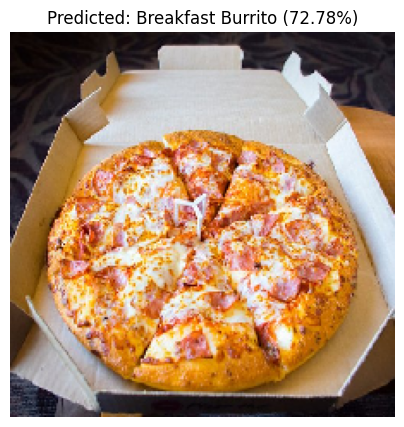


Prediction Output Payload:
{
    "label_name": "breakfast_burrito",
    "display_name": "Breakfast Burrito",
    "class_id": 9,
    "confidence_rate": "72.78%",
    "top_3_predictions": [
        {
            "class_id": 9,
            "label_name": "breakfast_burrito",
            "display_name": "Breakfast Burrito",
            "confidence_rate": "72.78%"
        },
        {
            "class_id": 2,
            "label_name": "baklava",
            "display_name": "Baklava",
            "confidence_rate": "9.41%"
        },
        {
            "class_id": 53,
            "label_name": "hamburger",
            "display_name": "Hamburger",
            "confidence_rate": "4.96%"
        }
    ]
}


In [16]:
# ==========================================================
# STEP 6: PREDICTION FUNCTION & INTERACTIVE IMAGE UPLOAD
# ==========================================================
def predict_uploaded_image(image_path, model, class_names, top_k=3):
    """
    Takes an image path and returns structured predictions matching team requirements.
    """
    # Load and preprocess image
    img = tf.keras.utils.load_img(image_path, target_size=(224, 224))
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = tf.expand_dims(img_array, axis=0)
    img_preprocessed = tf.keras.applications.mobilenet_v2.preprocess_input(img_batch)

    # Inference
    preds = model.predict(img_preprocessed, verbose=0)[0]

    # Get top-k indices
    top_indices = np.argsort(preds)[::-1][:top_k]

    # Primary top prediction details
    top_idx = int(top_indices[0])
    raw_label = class_names[top_idx]
    display_name = raw_label.replace("_", " ").title()
    confidence = float(preds[top_idx])

    # Format Top 3 list
    top_3_list = []
    for idx in top_indices:
        i = int(idx)
        top_3_list.append({
            "class_id": i,
            "label_name": class_names[i],
            "display_name": class_names[i].replace("_", " ").title(),
            "confidence_rate": f"{preds[i] * 100:.2f}%"
        })

    # Output dictionary matching user requirements
    output_payload = {
        "label_name": raw_label,
        "display_name": display_name,
        "class_id": top_idx,
        "confidence_rate": f"{confidence * 100:.2f}%",
        "top_3_predictions": top_3_list
    }

    return output_payload, img

# Interactive Upload Section
print("\n" + "="*50)
print("UPLOAD AN IMAGE FOR FOOD PREDICTION")
print("="*50)

uploaded = files.upload()

for filename in uploaded.keys():
    print(f"\nProcessing uploaded image: {filename}...")

    # Run prediction
    result, original_img = predict_uploaded_image(filename, model, class_names)

    # Display Image
    plt.figure(figsize=(5, 5))
    plt.imshow(original_img)
    plt.axis("off")
    plt.title(f"Predicted: {result['display_name']} ({result['confidence_rate']})")
    plt.show()

    # Display Formatted Prediction JSON Output
    print("\nPrediction Output Payload:")
    print(json.dumps(result, indent=4))